# Sparse-scaling benchmark: physical properties

A cell doubled `d` times is still bulk Si, so every property per primitive cell must look the same
at every size. Each figure shows one sparse pipeline. The colored lines are its sizes, and the
dashed black line is the dense reference on the primitive cell (`reference_d00`).

The curves come from [observables.py](observables.py), which normalizes them per primitive cell.
Tensor quantities show the `xx` component, and section 8 checks the components that cubic
symmetry zeroes. PDOS is left out. A pipeline that does not run a property has no panel for it:
the interior-window pipelines skip doping and the dielectric tensor, and only `sparse_curvature`
gives the Hall and Nernst tensors, the Kubo linear response and the effective masses. Section 9
lists the properties that are not tested, and why.

A note after each figure explains the curves that do not overlap. Its numbers come from the
`sparse` ladder (d = 0–7) at commit `0708029`, and for the `sparse_curvature` properties from that
ladder (d = 0–7) at commit `d814a35`.

The offset from the dense reference has two causes, measured at d = 0 on a 16³ mesh. Without
both, the sparse result matches the dense one to 10⁻⁷:

- **The `bond_order 36` cutoff.** It shifts the bands, by up to 0.26 eV at Γ in the lowest band.
  DoS, σ, κ and `cond_xx` move by 2–3%, S and PF by 5%, doping μ by 9 meV, ε″ and ε′ by 8–10%,
  the Hall trace by 15–19% and `inv_mass_dos` by 45%. Every pipeline has this offset at every d.
- **Different sets of bands.** The dense reference sums the interband terms over its `bnd` = 9
  well-projected bands. In the runs here, the sparse pass summed over every solved state: 16 at
  d = 0, 7 of them placeholders at the PAO shift. ε′ and the quantities derived from it then
  differed by 16–79%, even without the cutoff. The sparse engine now drops every state from
  0.2 eV below the shift up (`shift_margin`), so new runs only keep the window effect: fewer real
  conduction bands per cell are solved as d grows. The band-diagonal properties (DoS, transport,
  conductivity, doping) never depended on it.

The notebook reads the output files directly, so it also works while the ladder is still running.

In [1]:
import glob
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, os.path.abspath('.'))
import observables
from config import CONFIG

ROOT = os.environ.get('BENCH_OUTPUT_ROOT', CONFIG['output_root'])
PIPELINES = [name for name, p in CONFIG['pipelines'].items() if p['enabled'] and p['sparse']]
REFERENCE = 'reference_d00'

# palette: deep blue, vermillion, amber, then Okabe-Ito
PALETTE = ['#004488', '#D55E00', '#FFC20A', '#009E73', '#56B4E9', '#CC79A7', '#000000']
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})


def load_case(path):
    if not os.path.exists(os.path.join(path, 'record.json')):
        return None
    rec = observables.load_record(path)
    if rec.get('status') != 'ok':
        print('skipping %s: status %s' % (os.path.basename(path), rec.get('status')))
        return None
    return {
        'd': rec['case']['d'],
        'nawf': rec['hamiltonian']['nawf'],
        'curves': observables.load(path, pdos=False, optics=True),
    }


ref_case = load_case(os.path.join(ROOT, REFERENCE))
ref = ref_case['curves'] if ref_case else {}
if not ref:
    print('no finished %s yet: the figures show the sparse sizes only' % REFERENCE)

runs = {}
for pipeline in PIPELINES:
    paths = sorted(glob.glob(os.path.join(ROOT, pipeline + '_d[0-9][0-9]')))
    cases = [c for c in map(load_case, paths) if c is not None]
    if cases:
        runs[pipeline] = cases
        print('%-20s d = %s' % (pipeline, ', '.join(str(c['d']) for c in cases)))

skipping sparse_d07: status running
sparse               d = 0, 1, 2, 3, 4, 5, 6


skipping sparse_curvature_d08: status running
sparse_curvature     d = 0, 1, 2, 3, 4, 5, 6, 7


In [2]:
# name: (title, x label, y label)
LABELS = {
    'dos': ('DoS per primitive cell', 'E - E$_F$ (eV)', 'states/eV'),
    'doping_mu': ('μ at p = 10$^{18}$ cm$^{-3}$', 'T (K)', 'μ (eV)'),
    'sigma_xx': ('σ$_{xx}$/τ', 'μ (eV)', '1/(Ω m s)'),
    'seebeck_xx': ('Seebeck S$_{xx}$', 'μ (eV)', 'V/K'),
    'kappa_xx': ('κ$^{el}_{xx}$/τ', 'μ (eV)', 'W/(m K s)'),
    'pf_xx': ('power factor/τ, xx', 'μ (eV)', 'W/(m K$^2$ s)'),
    'hall_trace': ('Hall tensor trace', 'μ (eV)', 'm$^3$/C'),
    'hall_xyz': ('Hall R$_{xy,z}$', 'μ (eV)', 'm$^3$/C'),
    'hall_xzy': ('Hall R$_{xz,y}$', 'μ (eV)', 'm$^3$/C'),
    'hall_yzx': ('Hall R$_{yz,x}$', 'μ (eV)', 'm$^3$/C'),
    'nernst_xyz': ('Nernst N$_{xyz}$', 'μ (eV)', 'V/(K T)'),
    'nernst_yxz': ('Nernst N$_{yxz}$', 'μ (eV)', 'V/(K T)'),
    'sigma_xy': ('σ$_{xy}$/τ ÷ max |σ$_{xx}$|', 'μ (eV)', ''),
    'sigma_xz': ('σ$_{xz}$/τ ÷ max |σ$_{xx}$|', 'μ (eV)', ''),
    'sigma_yz': ('σ$_{yz}$/τ ÷ max |σ$_{xx}$|', 'μ (eV)', ''),
    'seebeck_xy': ('S$_{xy}$ ÷ max |S$_{xx}$|', 'μ (eV)', ''),
    'kappa_xy': ('κ$^{el}_{xy}$ ÷ max |κ$_{xx}$|', 'μ (eV)', ''),
    'pf_xy': ('PF$_{xy}$ ÷ max |PF$_{xx}$|', 'μ (eV)', ''),
    'hall_zero': ('RMS of the 6 vanishing R$_{ij,k}$ ÷ max |R$_{xy,z}$|', 'μ (eV)', ''),
    'nernst_zero': ('RMS of the 21 vanishing N$_{ijk}$ ÷ max |N$_{xyz}$|', 'μ (eV)', ''),
    'lr_cond_xx': ('Kubo σ$_{xx}$(μ)', 'μ (eV)', 'S/cm'),
    'lr_cond_xy': ('Kubo σ$_{xy}$(μ)', 'μ (eV)', 'S/cm'),
    'ahc_xy': ('anomalous Hall σ$_{xy}$', 'μ (eV)', 'S/cm'),
    'cond_xx': ('σ$_{xx}$(E), band-diagonal', 'E - E$_F$ (eV)', ''),
    'cond_xy': ('σ$_{xy}$(E), band-diagonal', 'E - E$_F$ (eV)', ''),
    'epsi_xx': ('ε″$_{xx}$', 'ħω (eV)', ''),
    'epsr_xx': ('ε′$_{xx}$', 'ħω (eV)', ''),
    'eels_xx': ('EELS, -Im 1/ε$_{xx}$', 'ħω (eV)', ''),
    'refl_xx': ('reflectivity R$_{xx}$', 'ħω (eV)', ''),
    'nref_xx': ('refractive index n$_{xx}$', 'ħω (eV)', ''),
    'kref_xx': ('extinction κ$_{xx}$', 'ħω (eV)', ''),
    'alpha_xx': ('absorption α$_{xx}$', 'ħω (eV)', '1/m'),
    'sigmar_xx': ('Re σ$_{xx}$(ω)', 'ħω (eV)', ''),
    'sigmai_xx': ('Im σ$_{xx}$(ω)', 'ħω (eV)', ''),
    'inv_mass_dos': ('Σ g(E - E$_{nk}$) / m$^{dos}_{nk}$', 'E - E$_F$ (eV)', '1/(m$_e$ eV)'),
    'inv_mass_trace': ('Σ g(E - E$_{nk}$) tr m$^{-1}_{nk}$ / 3', 'E - E$_F$ (eV)', '1/(m$_e$ eV)'),
}

# curves that span many decades (the Hall and Nernst tensors diverge in the gap,
# where the carrier density vanishes): symlog y axis with this linear threshold
SYMLOG = {
    'hall_trace': 1e-11,
    'hall_xyz': 1e-11,
    'hall_xzy': 1e-11,
    'hall_yzx': 1e-11,
    'nernst_xyz': 1e5,
    'nernst_yxz': 1e5,
}


def symlog(ax, linthresh):
    # symlog y axis with at most about five decades labelled on each side
    ax.set_yscale('symlog', linthresh=linthresh)
    top = np.log10(max(abs(y) for y in ax.get_ylim()))
    exps = np.arange(np.log10(linthresh) + 1, np.floor(top) + 1)
    exps = exps[::-1][:: max(1, -(-len(exps) // 5))]
    ax.set_yticks([0.0] + [s * 10.0**e for e in exps for s in (-1, 1)])


def style(d):
    return dict(color=PALETTE[d % len(PALETTE)], ls=('-', '--', ':')[d // len(PALETTE)], lw=1.1)


def describe(pipeline):
    sc = CONFIG['pipelines'][pipeline].get('sparse_config', {})
    parts = ['bond_order %d' % sc['bond_order']] if 'bond_order' in sc else []
    w = sc.get('interior_window')
    if w is None:
        parts.append('window from the property ranges')
    elif w:
        parts.append('interior window [%.1f, %.1f] eV' % (w['elo'], w['ehi']))
    else:
        parts.append('interior window from the property ranges')
    return '%s: %s' % (pipeline, ', '.join(parts))


def show(names, ncol=3, normalized=False):
    # one figure per pipeline, one panel per property it ran; normalized
    # divides every curve by its 'scale' (the norm of its deviation)
    for pipeline, cases in runs.items():
        present = [n for n in names if any(n in c['curves'] for c in cases)]
        if not present:
            continue
        nc = min(ncol, len(present))
        nr = -(-len(present) // nc)
        fig, axes = plt.subplots(nr, nc, figsize=(4.4 * nc, 3.2 * nr), squeeze=False)
        legend = {}
        for ax, name in zip(axes.flat, present):
            curves = [(c, c['curves'][name]) for c in cases if name in c['curves']]
            norm = lambda cv: cv['scale'] if normalized and cv['scale'] else 1.0
            for c, cv in curves:
                ax.plot(
                    cv['x'],
                    cv['y'] / norm(cv),
                    label='d=%d (nawf %d)' % (c['d'], c['nawf']),
                    **style(c['d']),
                )
            if name in ref:
                r = ref[name]
                ax.plot(r['x'], r['y'] / norm(r), 'k--', lw=1.0, label='dense reference')
            if name in SYMLOG:
                symlog(ax, SYMLOG[name])
            ax.set_xlim(
                min(cv['x'].min() for _, cv in curves), max(cv['x'].max() for _, cv in curves)
            )
            cuts = [cv['xmax'] for _, cv in curves if cv['xmax'] is not None]
            if cuts:
                ax.axvline(min(cuts), color='#888888', lw=0.8)
            title, xlabel, ylabel = LABELS[name]
            ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
            legend.update(zip(*reversed(ax.get_legend_handles_labels())))
        for ax in axes.flat[len(present) :]:
            ax.axis('off')
        fig.suptitle(describe(pipeline))
        fig.tight_layout()
        fig.legend(
            legend.values(), legend.keys(), loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8
        )
        plt.show()

## 1. Density of states and doping

The DoS per primitive cell, and the chemical potential against temperature at a p-type doping of
10¹⁸ cm⁻³. The interior-window DoS covers the window only.

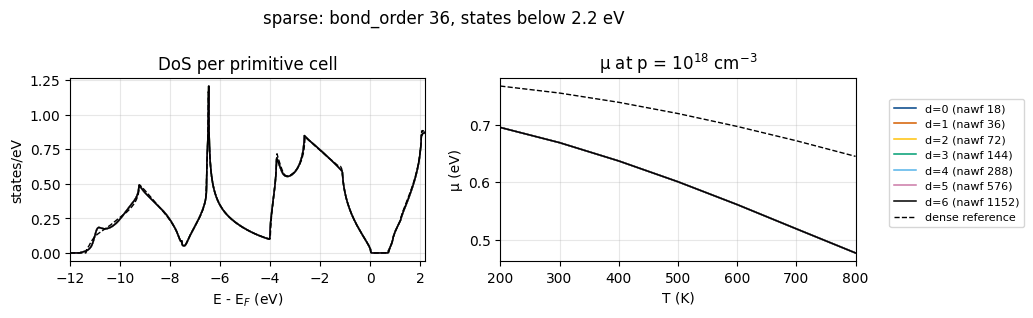

In [3]:
show(['dos', 'doping_mu'], ncol=2)

**Why μ(T) moves with d.** The DoS curves overlap to 5×10⁻⁴. μ splits into three groups
instead: d = 0–2, d = 3–5 (about 0.2 k_BT lower) and d = 6–7 (about 0.6 k_BT higher).

- **μ is set by numerical error, not by the doping.** `do_doping` solves ∫ 2 g(E) f(E) dE =
  nelec − pΩ. At p = 10¹⁸ cm⁻³, pΩ is 4×10⁻⁵ electrons per primitive cell. Integrating the
  DoS on its 14 meV grid already loses 2–3×10⁻⁴ electrons per cell at every d, 5–8 times the
  doping. So μ lands near the conduction-band edge (0.5–0.7 eV) instead of near the valence-band
  top, where a p-type level belongs. Any small change in the DoS then moves it by a fraction of
  k_BT.
- **The DoS change that moves μ is one feature at −7.5 eV.** It appears at d = 3 and changes
  again at d = 6, the sizes where z is doubled (2×2×2 and 4×4×4 primitive cells). From d = 3 on,
  the folded cell maps Si's X and L points onto its own Γ, so their states join larger degenerate
  groups. Inside a group whose velocity blocks do not commute (Si's own multiplets mixed with
  folded copies), the velocities are still paired one direction at a time. That changes the
  adaptive smearing width of a few states. The integrated change is +3×10⁻⁵ electrons at d = 3
  and −1.2×10⁻⁴ at d = 6, the size of the doping itself. This mechanism is a hypothesis that
  has not been checked state by state.
- **Making this a real check:** use p ≳ 10²⁰ cm⁻³ (pΩ ≈ 4×10⁻³), or a much finer energy grid
  for `doping`.

## 2. Boltzmann transport

Constant relaxation time, at 300 K, against the chemical potential. The Hall tensor trace needs
the full spectrum at every k-point, so only `sparse_curvature` has it; its y axis is symlog,
because the Hall coefficient diverges in the gap (0.05–0.7 eV here).

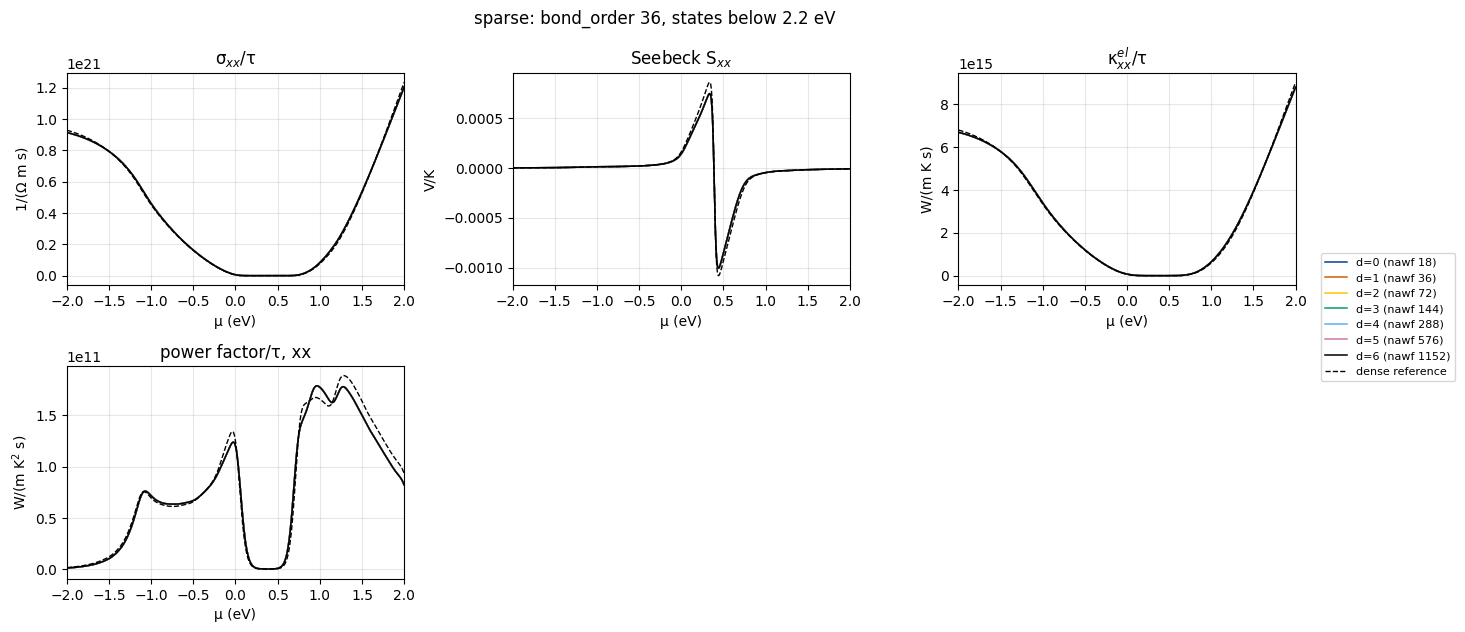

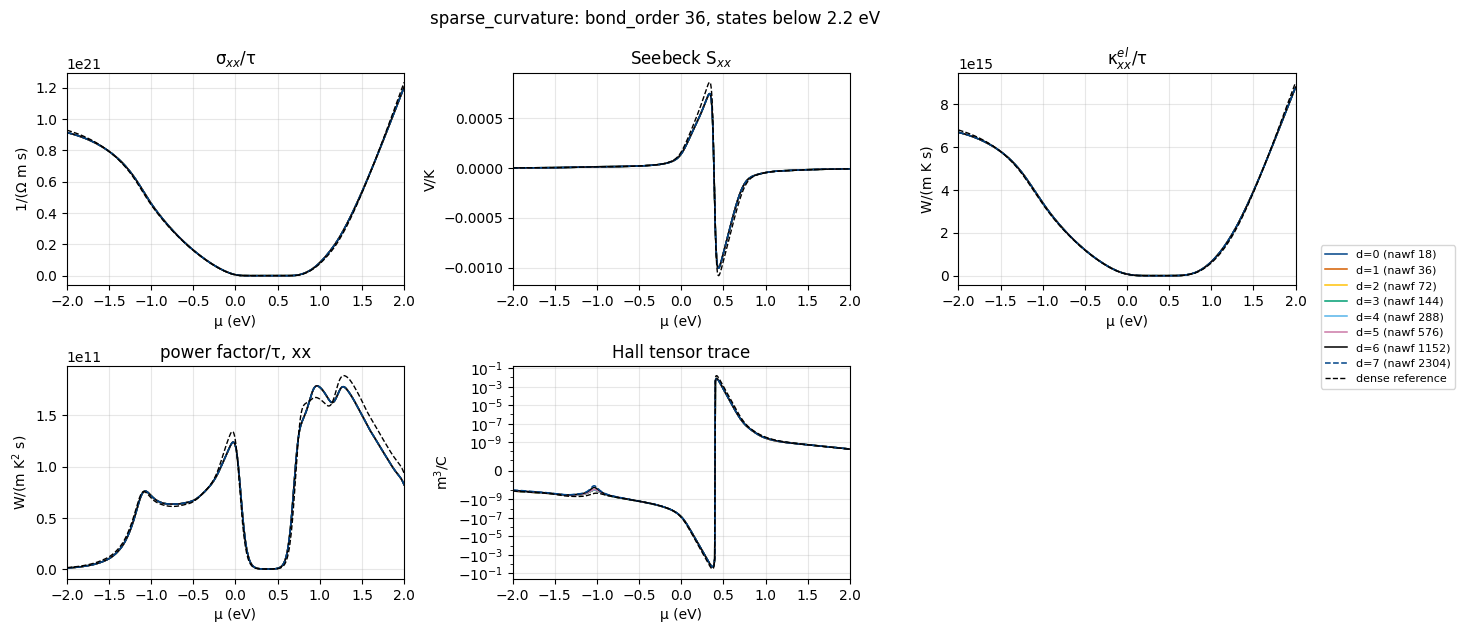

In [4]:
show(['sigma_xx', 'seebeck_xx', 'kappa_xx', 'pf_xx', 'hall_trace'])

σ, S, κ and PF overlap to better than 10⁻⁴ at every d.

**The Hall trace drifts only in the gap.** Against d = 0 it moves by at most 2×10⁻⁴ at d = 1–5,
4×10⁻² at d = 6 and 6×10⁻² at d = 7 (relative L2 over the whole scan). All of it sits in the gap
(0.05–0.7 eV). Outside the gap the components agree to 2×10⁻⁶ (section 3). In the gap the Hall
coefficient is R ∝ σ_H/σ², a ratio of two numbers that both vanish with the intrinsic carrier
density, so tiny absolute changes in either become large relative changes. The 0.4 offset from
the dense reference is concentrated there too (the cutoff narrows the gap).

## 3. Hall and Nernst tensors

The three Hall components with three different indices, R_xy,z, R_xz,y and R_yz,x, are equal in
magnitude in a cubic crystal; their trace is the panel above. The Nernst tensor N_ijk follows
from the Hall coefficient and the first-order Boltzmann tensor. Both need the band curvature, so
only `sparse_curvature` has them.

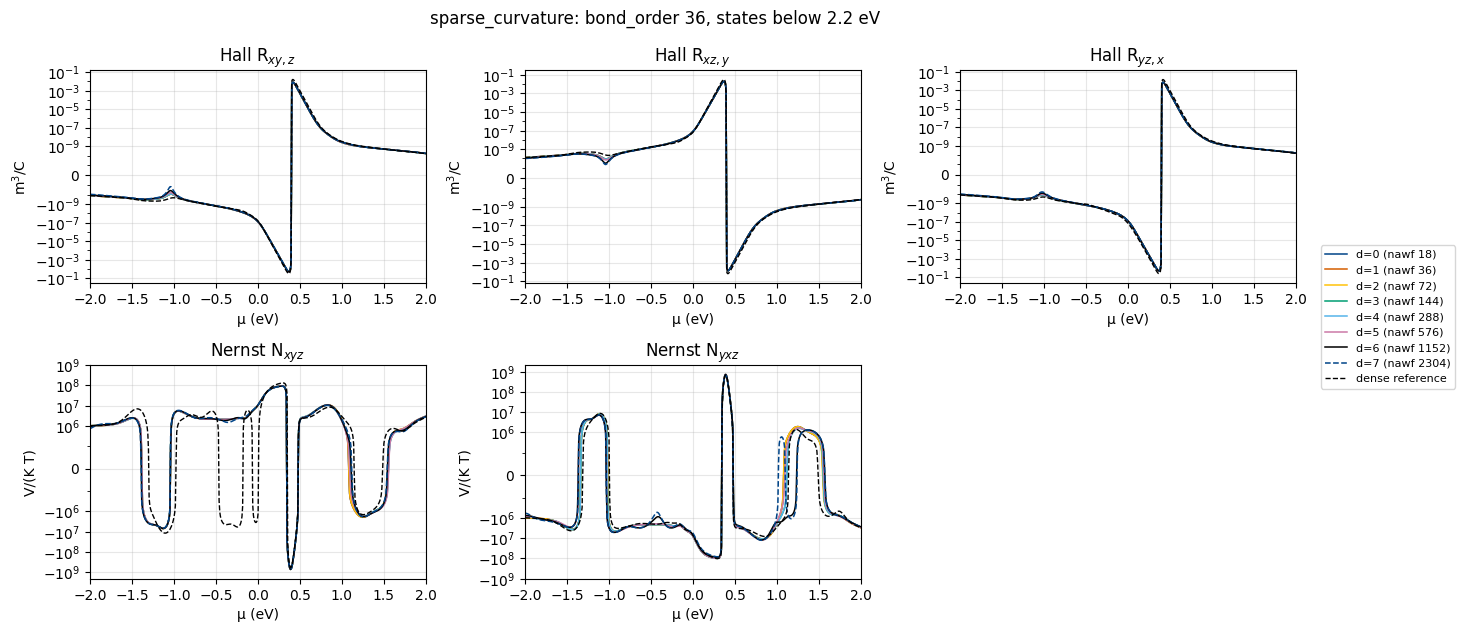

In [5]:
show(['hall_xyz', 'hall_xzy', 'hall_yzx', 'nernst_xyz', 'nernst_yxz'])

**Exact outside the gap, drift inside it.** Measured on `sparse_curvature` d = 0–7:

- Outside the gap (below 0 and above 0.75 eV) every Hall component of d = 5–7 matches d = 0 to
  2×10⁻⁶ of its RMS, at every μ. Inside the gap, the relative L2 drift of R_xy,z is 2×10⁻⁵ at
  d = 1, 8×10⁻⁵ at d = 2–4, 7×10⁻³ at d = 5, 7×10⁻² at d = 6 and 0.11 at d = 7, for the reason
  given under the Hall trace.
- The Nernst tensor drifts over the whole scan: N_yxz by up to 3.5×10⁻² of its RMS outside the
  gap at d = 7, and 0.8 inside it. It contains the energy derivative of the Hall coefficient,
  which amplifies the small changes in the band curvature that folding brings (see section 7).
- Against the dense reference, d = 0 differs by 0.4 (Hall) and 0.06–0.27 (Nernst). For the Hall
  tensor almost all of it is in the gap; the Nernst tensor differs everywhere, with sign changes
  at other μ. The reference itself is not cubic: its largest |R_yz,x| is 28% above its largest
  |R_xy,z|, while the sparse components agree with each other to 0.6%.

**Why the Nernst tensor differs from the dense reference** (24³ tests at d = 0, 2026-10-24):

- **The `bond_order 36` cutoff, amplified twice.** Without it (`hopping_threshold=0`), sparse
  matches dense to 10⁻⁷ in σ and 3×10⁻⁶ in S. With it, the band energies move by a median of
  7.5 meV, but the band curvature tr m⁻¹ moves by 14%: the hoppings beyond the cutoff (32 Bohr)
  hold 5% of Σ|H(R)|, 15% of Σ d|H| (velocities) and 36% of Σ d²|H| (curvature). The Hall
  coefficient, built from the curvature, then moves by 30% outside the gap.
- **Cancellation.** `do_transport` builds N = R_H L⁽¹⁾ + σ⁻¹ L⁽¹·ᴴᵃˡˡ⁾, and the two terms nearly
  cancel (Sondheimer). Outside the gap |N| is typically 26% of |term 1| + |term 2|, and below 4%
  at one μ in ten. Each term moves by 40–45% with the cutoff, N by 60%, and its sign changes
  where it is small.
- **A small part from degenerate states.** Without the cutoff, Hall and Nernst still differ
  from dense by 6×10⁻⁴–3×10⁻² (N_yxz 0.1 outside the gap). The curvature of 84 of 24 160 states
  near the gap differs by more than 0.1%, 48 of them in degenerate groups, where dense and
  sparse resolve the curvature in different gauges.

## 4. Band-diagonal conductivity

σ_xy vanishes by cubic symmetry, so its curve should stay at zero next to σ_xx.

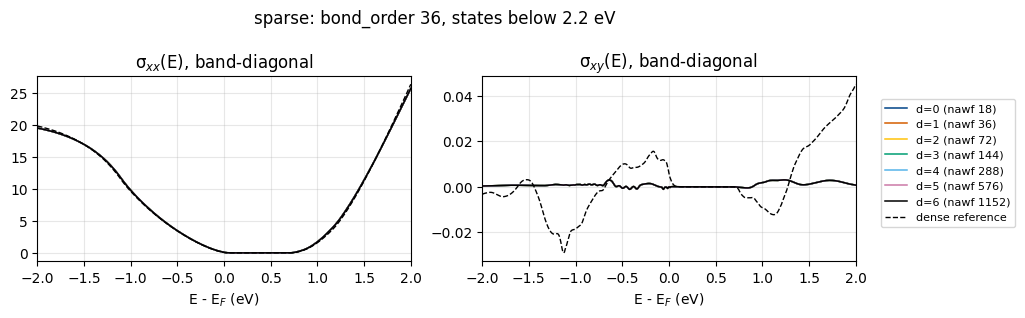

In [6]:
show(['cond_xx', 'cond_xy'], ncol=2)

**Why σ_xy differs between sizes.** σ_xx overlaps to 5×10⁻⁴. σ_xy should vanish by cubic
symmetry, and it is only 1–2×10⁻⁴ of σ_xx at every d, d = 0 included. The panel shows a residual
on its own scale, not a physical signal.

- σ_xy sums v_x v_y over states, so it cancels only if every degenerate group pairs its velocity
  components consistently. Groups whose velocity blocks commute (folded copies) are paired jointly,
  and the others one direction at a time. That leaves a small residual even at d = 0.
- Folding changes which groups are mixed, so the pattern of the residual changes with d. Its size
  does not grow.

## 5. Kubo linear response

`linear_response` sums over every pair of states, so it needs the full spectrum and only
`sparse_curvature` runs it. Shown are the charge conductivity σ_xx(μ) with a Lorentzian
broadening of 0.05 eV, its xy component, and the anomalous Hall conductivity σ_xy. Without spin
polarization and with time-reversal symmetry, the anomalous Hall conductivity of Si is exactly
zero, and so is σ_xy by cubic symmetry: both are measured on the scale of σ_xx.

In [7]:
show(['lr_cond_xx', 'lr_cond_xy', 'ahc_xy'])

**Expected** (added 2026-10-24, no ladder runs yet; a 12³ smoke test at d ≤ 1):

- σ_xx at d = 1 matches d = 0 to 5×10⁻⁷, σ_xy and the anomalous Hall conductivity stay at
  4×10⁻⁴ and 10⁻¹³ of σ_xx.
- Sparse d = 0 is 18% above the dense reference, 28–50% in the conduction band (the Boltzmann
  σ_xx differs by 5% there). The Kubo formula of `linear_response_eqn1` weights each state n with
  a Lorentzian at E_n but sums |v_nm|² over every state m, with no energy factor. The dense
  reference includes its 9 placeholder states at the PAO shift in that sum, and the sparse pass
  drops them (`shift_margin`). It is the band-set effect of the introduction, and it does not
  depend on d.

## 6. Optical response

Kubo-Greenwood dielectric function and the optical constants built from it. The grey line is the
energy-window top minus 0.5 eV: above it, ε″ of a window run misses the transitions into states
above the window. ε′ and everything derived from it (EELS, R, n, κ, α, σ(ω)) need transitions at
all energies, so for a window run they differ from the reference at every ω.

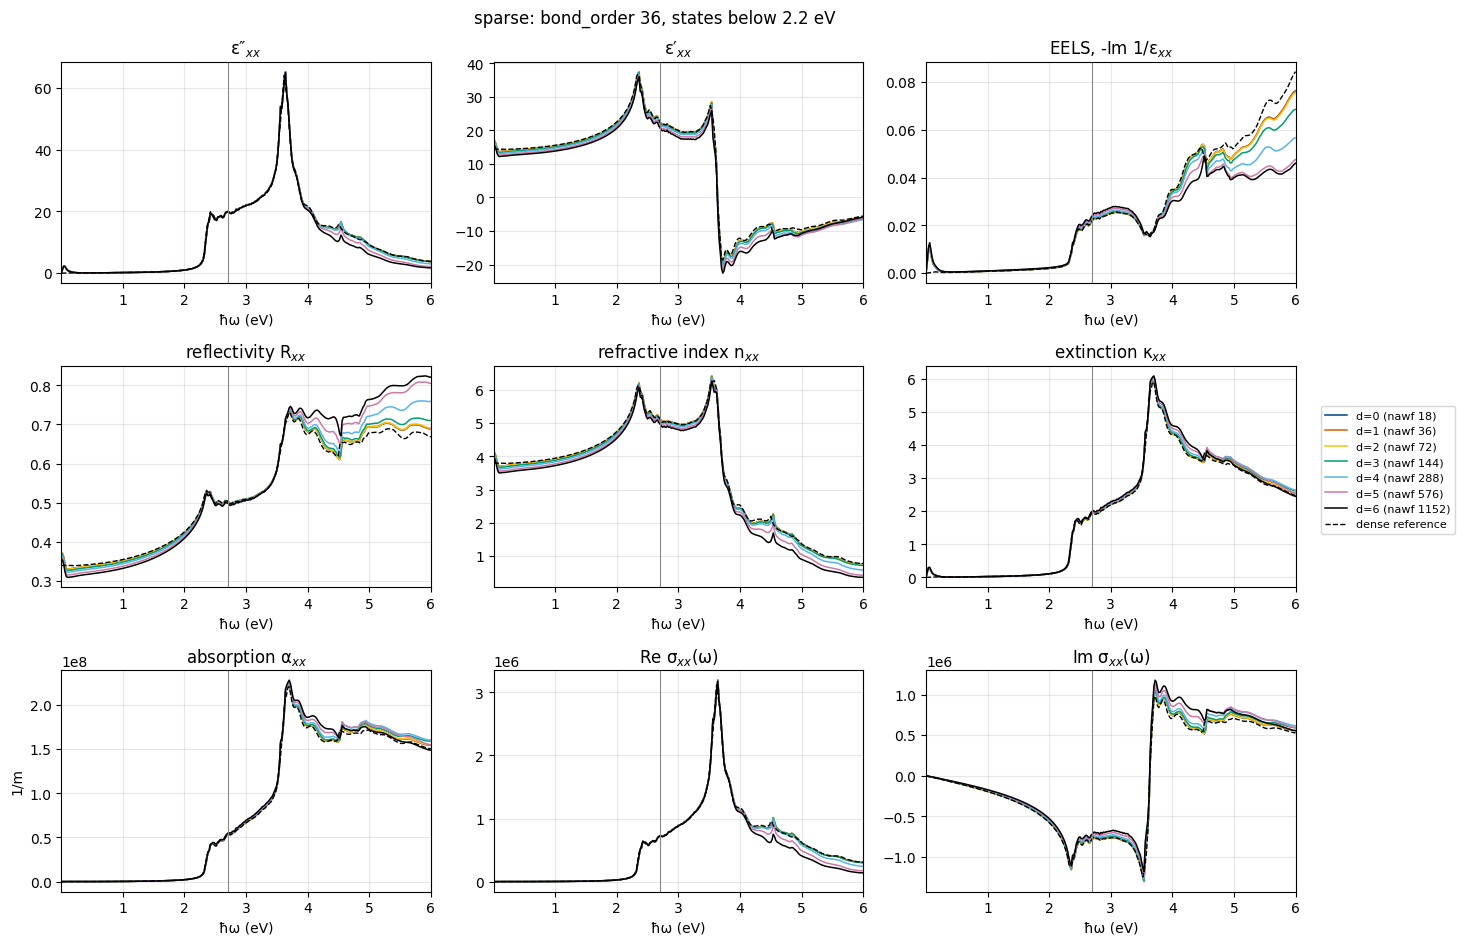

In [8]:
show(
    [
        'epsi_xx',
        'epsr_xx',
        'eels_xx',
        'refl_xx',
        'nref_xx',
        'kref_xx',
        'alpha_xx',
        'sigmar_xx',
        'sigmai_xx',
    ]
)

**Why the optical curves separate.**

- **ε″ above the grey line: the window, not doubling.** The sparse sum runs over every solved
  state, and the solver keeps enough states to reach 3.2 eV at every k-point. Per primitive cell
  that is 16 of 18 states at d = 0 (n = 18 is too small for anything but the dense kernel, so
  nearly everything is solved), 10.5 at d = 1 and 5.4 at d = 7. On a doubled cell, the k-point
  with the most states below the window top sets the count for a whole group of folded k-points,
  so the per-cell count falls toward the average. d = 0 therefore still contains transitions far
  above the window, and each doubling drops more of them. Above the line the curves are not
  expected to agree.
- **ε″ below the line: degenerate groups (fixed after these runs).** The deviation from d = 0
  grows from 4×10⁻⁴ at d = 1 to 4×10⁻³ at d = 7. On a folded cell, `get_degeneracies` sometimes
  listed a group twice, so `perturb_split` rotated it twice. And a group holding copies of a
  multiplet from k and −k had each velocity direction sorted across both copies. Either way, the
  momentum matrix elements and the adaptive pair widths (`delta2`) belonged to different
  states. The mesh pass now merges repeated groups and splits a group into its copies before
  resolving it. On a 16³ test ladder this cut the drift from 5×10⁻³–10⁻² to 1–2×10⁻³, and what
  remains is the window: d = 1 matches d = 0 to 10⁻⁹ once both keep the same states. The
  transitions into states that only d = 0 solves have adaptive Gaussian tails reaching below
  the line.
- **ε′ and everything built from it (EELS, R, n, κ, α, σ(ω)) at every ω.** ε′ at any frequency
  depends on transitions at all energies (Kramers–Kronig). The missing high-energy transitions
  lower it everywhere, more at each d: below 2 eV it is 10% lower at d = 1 and 22% lower at
  d = 7. The derived quantities inherit this.

## 7. Effective masses

The per-state masses of `effective_masses_0.dat` cannot be compared line by line across sizes,
so they are shown as smeared densities per k-point of the primitive cell: of the inverse DoS
mass, Σ g(E − E_nk) / m_dos,nk, and of the mean inverse principal mass, Σ g(E − E_nk) tr m⁻¹_nk / 3,
which is the Laplacian of the band energy. The file lists the three principal masses in no fixed
order, so only symmetric functions of them, like these two, compare across runs.

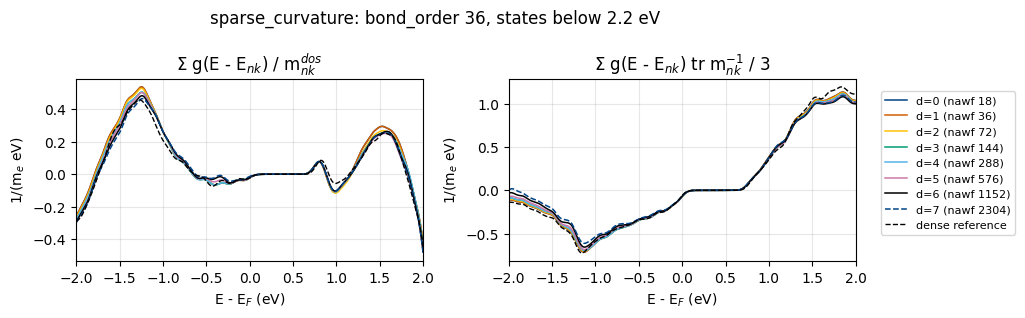

In [9]:
show(['inv_mass_dos', 'inv_mass_trace'], ncol=2)

**The band curvature drifts with d.** Measured on `sparse_curvature` d = 0–7, relative L2 against
d = 0:

| d | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|
| `inv_mass_dos` | 2×10⁻³ | 5×10⁻² | 9×10⁻² | 9×10⁻² | 0.14 | 0.15 | 0.19 |
| `inv_mass_trace` | 4×10⁻⁴ | 1×10⁻² | 3×10⁻² | 3×10⁻² | 4×10⁻² | 7×10⁻² | 0.10 |

- The trace drifts half as much as 1/m_dos: 1/m_dos jumps wherever one principal curvature
  passes through zero, the trace does not.
- What is left is in the curvature itself, and it is smallest near the gap: at d = 7 it reaches
  1–5×10⁻² of the RMS within 0.5 eV of the gap and 0.24 at −2 eV. A likely cause, not checked
  state by state: the second-order term of `band_curvature_k` sums |v_nm|²/(E_n − E_m) over
  pairs, and inside a degenerate group the curvature is still resolved one direction at a time,
  so folding, which multiplies the groups, changes it. Away from the gap the bands are denser,
  and so are the near-degenerate pairs.
- Against the dense reference, d = 0 differs by 0.23 (`inv_mass_dos`) and 5×10⁻² (trace).

## 8. Cubic symmetry: components that must vanish

Si is cubic, so every off-diagonal component of σ, S, κ and PF vanishes, and so do the 6 Hall
components R_ij,k and the 21 Nernst components N_ijk with a repeated index. Each panel divides
the curve by the largest value of its symmetry-allowed partner (the norm `collect.py` also uses
for its deviation), so it reads as the relative size of the residual.

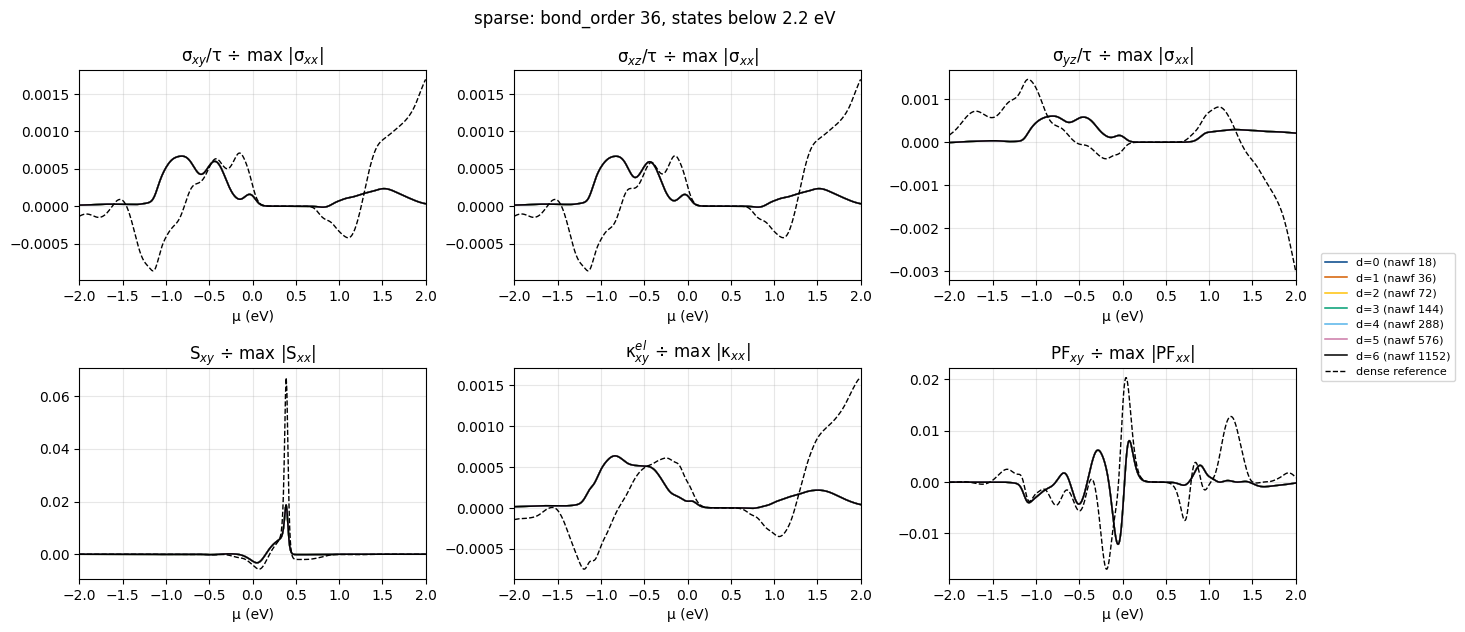

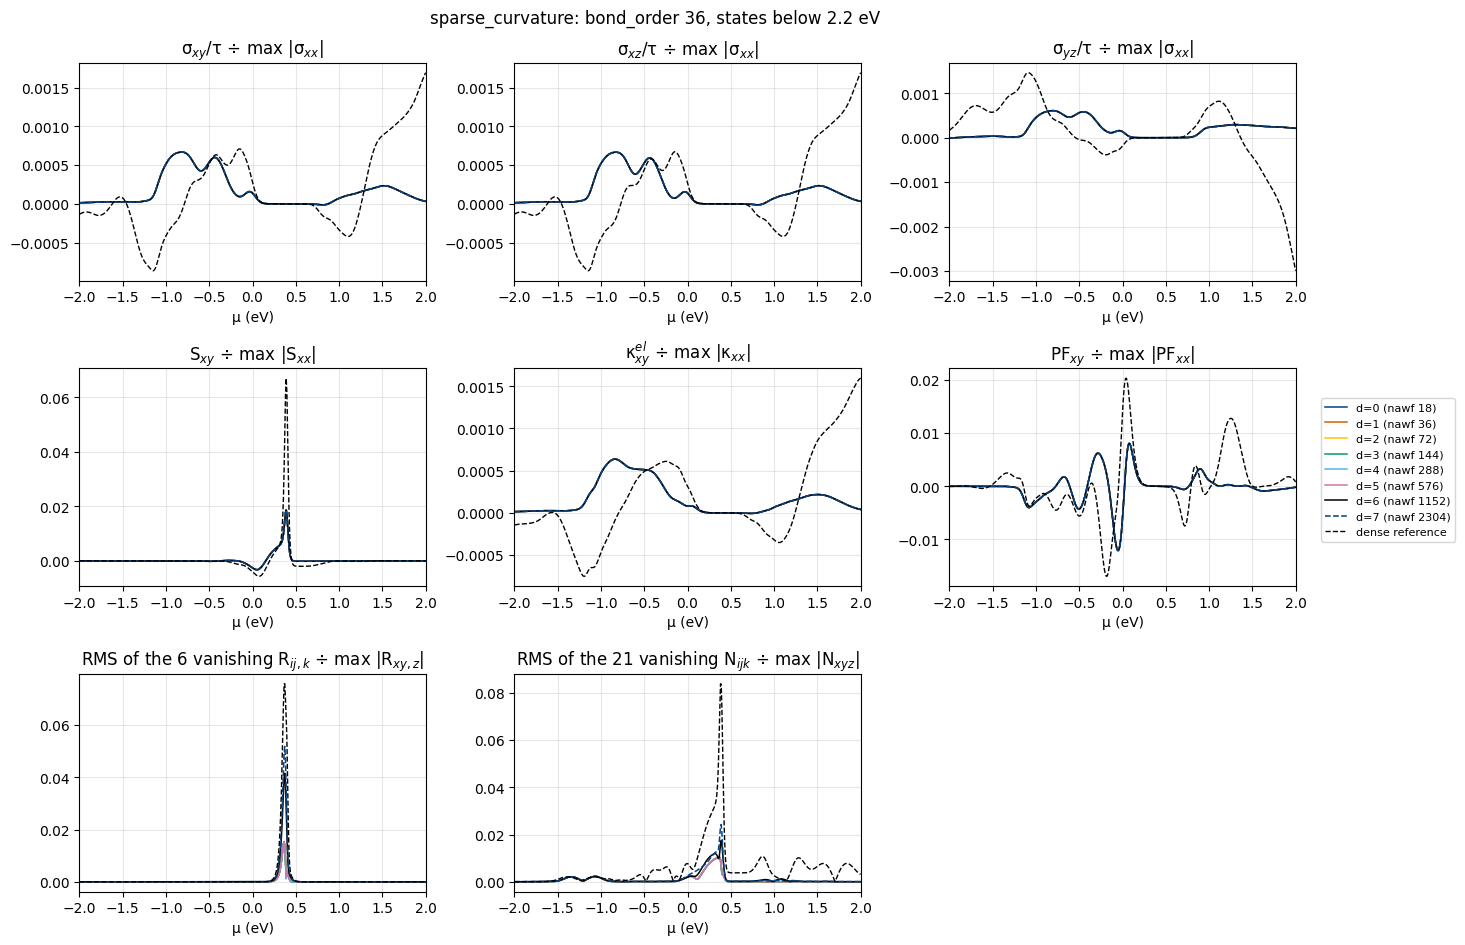

In [10]:
show(
    [
        'sigma_xy',
        'sigma_xz',
        'sigma_yz',
        'seebeck_xy',
        'kappa_xy',
        'pf_xy',
        'hall_zero',
        'nernst_zero',
    ],
    normalized=True,
)

**Small residuals that do not grow with d.**

- The off-diagonal Boltzmann components stay at 3×10⁻⁴ of the diagonal (σ_xy) at every d, and
  change by at most 3×10⁻⁸ (σ) and 3×10⁻⁷ (PF) between sizes in both `sparse` and
  `sparse_curvature`. They come from the band velocities alone, which are paired jointly inside
  degenerate groups (see `cond_xy` above).
- The RMS of the vanishing Hall and Nernst components is 1.5×10⁻³ and 2×10⁻³ of the scale at
  d = 0, and it grows with d, to 5×10⁻³ and 3×10⁻³ at d = 7, through the band curvature
  (section 7).
- The dense reference breaks cubic symmetry more: its residuals are 2–6 times larger (σ_xy
  5.6×10⁻⁴, Hall 9×10⁻³, Nernst 1.2×10⁻²). Its H(R) is not cubic away from the PAO grid.

## 9. What is not tested

- **PDOS**: left out of this notebook. `collect.py` still compares it.
- **Spin-orbit properties.** `spin_Hall`, `orbital_Hall`, `anomalous_Hall` (the Berry-curvature
  route) and `linear_response` with `'shc'` or `'ree'` stop without a relativistic calculation
  (`dftSO`), which example01 is not. `spin_texture` and `rashba_edelstein` run, but build the spin
  operator for a j-basis that a scalar-relativistic basis does not have, so their output means
  nothing here. The anomalous Hall conductivity is still tested, through
  `linear_response(response='ahc')`, which needs no spin operator. Si with `adhoc_spin_orbit` on
  the base cell would cover the rest. It needs a pipeline of its own, because it doubles `nawf`.
- **Per-k and per-path outputs**: `bands`, `fermi_surface`, `ipr`, `orbital_texture`,
  `berry_curvature`, `topology`, `site_projected_bands`, `wave_function_projection` and
  `berry_phase`. Doubling folds the bands, so these differ by construction.
- **`jdos`**: it reads the DFT eigenvalues on the QE grid, not the PAO Hamiltonian, so the sparse
  pipeline cannot change it.
- **`density`**: per cell it could be compared, by tiling the primitive-cell ρ(r) onto the doubled
  grid, but the benchmark does not run it yet.
- **Off-diagonal ε**: `dielectric_tensor` runs with `d_tensor='diag'`, so ε_xy (zero by symmetry)
  is not written.
- **Temperature dependence**: transport runs at 300 K only (`nt = 1`); doping scans 200–800 K.